In [2]:

# STEP 1: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# STEP 2: Download the official UCI dataset
!wget -q -O Online_Retail.xlsx "https://archive.ics.uci.edu/ml/machine-learning-databases/00352/Online%20Retail.xlsx"

# STEP 3: Load the Excel file
df = pd.read_excel("Online_Retail.xlsx")

# STEP 4: Display the first five rows
print("Dataset loaded successfully!")
display(df.head())


Dataset loaded successfully!


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


**DATA SET UNDERSTANDING**

In [3]:
# Number of rows and columns
print("Dataset Shape:", df.shape)

print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])


Dataset Shape: (541909, 8)
Total Rows: 541909
Total Columns: 8


In [4]:
# Display column names
print("Column Names:")
print(df.columns.tolist())

# Display dataset information
print("\nDataset Information:")
df.info()


Column Names:
['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [5]:

# Count missing values in each column
print("Missing Values:")
print(df.isnull().sum())

# Calculate missing value percentage
print("\nMissing Value Percentage:")
print((df.isnull().sum() / len(df) * 100).round(2))


Missing Values:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Missing Value Percentage:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     24.93
Country         0.00
dtype: float64


In [6]:

# Count duplicate rows
print("Total Duplicate Rows:", df.duplicated().sum())


Total Duplicate Rows: 5268


In [7]:

# Statistical summary
display(df.describe())


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


**`DATA CLEANING AND PROCESSING`**

In [8]:
# Create a copy of the original dataset
clean_df = df.copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", clean_df.shape)


Original dataset shape: (541909, 8)
Working dataset shape: (541909, 8)


In [9]:

# Count missing customer IDs before cleaning
missing_customers = clean_df["CustomerID"].isnull().sum()

# Remove records without CustomerID
clean_df = clean_df.dropna(subset=["CustomerID"]) #to remove rows(dropna) ... to remove columns(drop)

print("Missing CustomerID records removed:", missing_customers)
print("Remaining records:", len(clean_df))


Missing CustomerID records removed: 135080
Remaining records: 406829


In [10]:

# Count duplicates before removal
duplicate_count = clean_df.duplicated().sum()

# Remove duplicates
clean_df = clean_df.drop_duplicates()

print("Duplicate records removed:", duplicate_count)
print("Remaining records:", len(clean_df))


Duplicate records removed: 5225
Remaining records: 401604


In [11]:

# Count cancelled invoices
cancelled_count = clean_df["InvoiceNo"].astype(str).str.startswith("C").sum()

# Keep only non-cancelled invoices
clean_df = clean_df[
    ~clean_df["InvoiceNo"].astype(str).str.startswith("C")
]

print("Cancelled transactions removed:", cancelled_count)
print("Remaining records:", len(clean_df))


Cancelled transactions removed: 8872
Remaining records: 392732


In [12]:

# Count invalid records
negative_quantity = (clean_df["Quantity"] <= 0).sum()
invalid_price = (clean_df["UnitPrice"] <= 0).sum()

# Keep valid sales transactions
clean_df = clean_df[
    (clean_df["Quantity"] > 0) &
    (clean_df["UnitPrice"] > 0)
]

print("Invalid quantity records:", negative_quantity)
print("Invalid price records:", invalid_price)
print("Remaining records:", len(clean_df))


Invalid quantity records: 0
Invalid price records: 40
Remaining records: 392692


In [13]:

# Convert InvoiceDate to datetime
clean_df["InvoiceDate"] = pd.to_datetime(
    clean_df["InvoiceDate"],
    errors="coerce"
)

# Remove rows where date conversion failed
clean_df = clean_df.dropna(subset=["InvoiceDate"])

print(clean_df["InvoiceDate"].dtype)


datetime64[ns]


In [14]:

# Calculate total transaction value
clean_df["TotalAmount"] = (
    clean_df["Quantity"] * clean_df["UnitPrice"]
)

display(clean_df[
    ["InvoiceNo", "Quantity", "UnitPrice", "TotalAmount"]
].head())


,InvoiceNo,Quantity,UnitPrice,TotalAmount
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34


In [15]:

# Final cleaning report
print("========== DATA CLEANING REPORT ==========")

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Rows removed:", len(df) - len(clean_df))

print(
    "Percentage of rows retained:",
    round(len(clean_df) / len(df) * 100, 2), "%"
)

print("Remaining missing values:")
print(clean_df.isnull().sum())

print("Remaining duplicates:", clean_df.duplicated().sum())

print("Final dataset shape:", clean_df.shape)

print("==========================================")


========== DATA CLEANING REPORT ==========
Original rows: 541909
Cleaned rows: 392692
Rows removed: 149217
Percentage of rows retained: 72.46 %
Remaining missing values:
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
TotalAmount    0
dtype: int64
Remaining duplicates: 0
Final dataset shape: (392692, 9)


In [16]:

clean_df.to_csv("cleaned_online_retail.csv", index=False)

print("Cleaned dataset saved successfully!")


Cleaned dataset saved successfully!


In [17]:
clean_df.head(10)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,TotalAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom,15.30
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom,25.50
7,536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10
8,536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom,11.10
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom,54.08


**CALCULATING RFM METRICS**


The Three RFM Components

• Recency (R): How recently a customer made a purchase. Customers who bought something very recently are more engaged and likely to respond to new offers.    
• Frequency (F): How often a customer makes a purchase over a specific period. Higher frequency signals strong customer loyalty and repeat engagement.    
• Monetary Value (M): How much money a customer spends across their purchases. This helps identify high-spending vs. low-spending buyers.

In [18]:

# Find the last invoice date
last_date = clean_df["InvoiceDate"].max()

# Set snapshot date to one day after the last invoice
snapshot_date = last_date + pd.Timedelta(days=1)

print("Last Invoice Date:", last_date)
print("Snapshot Date:", snapshot_date)


Last Invoice Date: 2011-12-09 12:50:00
Snapshot Date: 2011-12-10 12:50:00


In [19]:

# Group transactions by CustomerID
rfm = clean_df.groupby("CustomerID").agg(

    # Recency: Days since last purchase
    Recency=("InvoiceDate",
             lambda x: (snapshot_date - x.max()).days),

    # Frequency: Number of unique invoices
    Frequency=("InvoiceNo", "nunique"),

    # Monetary: Total amount spent
    Monetary=("TotalAmount", "sum")

).reset_index()

# Display the first five customers
display(rfm.head())


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.60
1,12347.0,2,7,4310.00
2,12348.0,75,4,1797.24
3,12349.0,19,1,1757.55
4,12350.0,310,1,334.40


In [20]:

# Select one customer
customer_id = rfm["CustomerID"].iloc[0]

# Get all transactions for that customer
customer_data = clean_df[
    clean_df["CustomerID"] == customer_id
]

# Calculate manually
manual_recency = (
    snapshot_date - customer_data["InvoiceDate"].max()
).days

manual_frequency = customer_data["InvoiceNo"].nunique()

manual_monetary = customer_data["TotalAmount"].sum()

print("Customer ID:", customer_id)
print("Manual Recency:", manual_recency)
print("Manual Frequency:", manual_frequency)
print("Manual Monetary:", manual_monetary)

# Compare with RFM table
display(rfm[rfm["CustomerID"] == customer_id])


Customer ID: 12346.0
Manual Recency: 326
Manual Frequency: 1
Manual Monetary: 77183.6


,CustomerID,Recency,Frequency,Monetary
0,12346.0,326,1,77183.6


**RFM SCORING**

RECENCY SCORE

In [21]:

rfm["R_score"] = pd.qcut(
    rfm["Recency"],
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

display(rfm[["CustomerID", "Recency", "R_score"]].head(10))


,CustomerID,Recency,R_score
0,12346.0,326,1
1,12347.0,2,5
2,12348.0,75,2
3,12349.0,19,4
4,12350.0,310,1
5,12352.0,36,3
6,12353.0,204,1
7,12354.0,232,1
8,12355.0,214,1
9,12356.0,23,4


FREQUENCY SCORE

In [22]:

rfm["F_score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(rfm[["CustomerID", "Frequency", "F_score"]].head(10))


,CustomerID,Frequency,F_score
0,12346.0,1,1
1,12347.0,7,5
2,12348.0,4,4
3,12349.0,1,1
4,12350.0,1,1
5,12352.0,8,5
6,12353.0,1,1
7,12354.0,1,1
8,12355.0,1,1
9,12356.0,3,3


MONETARY SCORE

In [23]:

rfm["M_score"] = pd.qcut(
    rfm["Monetary"],
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

display(rfm[["CustomerID", "Monetary", "M_score"]].head(10))


,CustomerID,Monetary,M_score
0,12346.0,77183.60,5
1,12347.0,4310.00,5
2,12348.0,1797.24,4
3,12349.0,1757.55,4
4,12350.0,334.40,2
5,12352.0,2506.04,5
6,12353.0,89.00,1
7,12354.0,1079.40,4
8,12355.0,459.40,2
9,12356.0,2811.43,5


RFM SCORE

In [24]:

rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

display(rfm[
    ["CustomerID", "Recency", "Frequency", "Monetary",
     "R_score", "F_score", "M_score", "RFM_score"]
].head(10))


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,8,2506.04,3,5,5,355
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,4,114
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


CHECKING SCORE DISTRIBUTION

In [25]:

# Check score distribution
print("Recency Score Distribution:")
print(rfm["R_score"].value_counts().sort_index())

print("\nFrequency Score Distribution:")
print(rfm["F_score"].value_counts().sort_index())

print("\nMonetary Score Distribution:")
print(rfm["M_score"].value_counts().sort_index())

print("\nRFM Score Examples:")
display(rfm.head(10))


Recency Score Distribution:
R_score
1    865
2    843
3    858
4    904
5    868
Name: count, dtype: int64

Frequency Score Distribution:
F_score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

Monetary Score Distribution:
M_score
1    868
2    867
3    868
4    867
5    868
Name: count, dtype: int64

RFM Score Examples:


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score
0,12346.0,326,1,77183.60,1,1,5,115
1,12347.0,2,7,4310.00,5,5,5,555
2,12348.0,75,4,1797.24,2,4,4,244
3,12349.0,19,1,1757.55,4,1,4,414
4,12350.0,310,1,334.40,1,1,2,112
5,12352.0,36,8,2506.04,3,5,5,355
6,12353.0,204,1,89.00,1,1,1,111
7,12354.0,232,1,1079.40,1,1,4,114
8,12355.0,214,1,459.40,1,1,2,112
9,12356.0,23,3,2811.43,4,3,5,435


CUSTOMER SEGMENTATION

In [26]:

# Function to classify customers into segments

def segment(row):

    r = row["R_score"]
    f = row["F_score"]

    if r >= 4 and f >= 4:
        return "Champions"

    elif r >= 3 and f >= 3:
        return "Loyal Customers"

    elif r >= 4 and f <= 2:
        return "Potential Loyalists"

    elif r <= 2 and f >= 3:
        return "At Risk"

    elif r <= 2 and f <= 2:
        return "Lost"

    else:
        return "Others"


In [27]:

# Apply segmentation to every customer
rfm["Segment"] = rfm.apply(segment, axis=1)

# Display customer segments
display(rfm[
    ["CustomerID", "R_score", "F_score", "M_score", "RFM_score", "Segment"]
].head(10))


,CustomerID,R_score,F_score,M_score,RFM_score,Segment
0,12346.0,1,1,5,115,Lost
1,12347.0,5,5,5,555,Champions
2,12348.0,2,4,4,244,At Risk
3,12349.0,4,1,4,414,Potential Loyalists
4,12350.0,1,1,2,112,Lost
5,12352.0,3,5,5,355,Loyal Customers
6,12353.0,1,1,1,111,Lost
7,12354.0,1,1,4,114,Lost
8,12355.0,1,1,2,112,Lost
9,12356.0,4,3,5,435,Loyal Customers


In [28]:
#customers in each segment
segment_counts = rfm["Segment"].value_counts()

print("Customer Count by Segment:")
display(segment_counts)


Customer Count by Segment:


,count
Segment,
Champions,1139
Lost,1065
Loyal Customers,821
At Risk,643
Others,351
Potential Loyalists,319


In [29]:
#percentage of customers
segment_percentage = (
    rfm["Segment"].value_counts(normalize=True) * 100
).round(2)

print("Customer Percentage by Segment:")
display(segment_percentage)


Customer Percentage by Segment:


,proportion
Segment,
Champions,26.26
Lost,24.55
Loyal Customers,18.93
At Risk,14.82
Others,8.09
Potential Loyalists,7.35


In [30]:

# Check all segments
print("Unique Segments:")
print(rfm["Segment"].unique())

# Check total customers
print("\nTotal Customers:", len(rfm))

# Check customers assigned to segments
print("Segmented Customers:", rfm["Segment"].notnull().sum())

# Check missing segments
print("Missing Segments:", rfm["Segment"].isnull().sum())


Unique Segments:
['Lost' 'Champions' 'At Risk' 'Potential Loyalists' 'Loyal Customers'
 'Others']

Total Customers: 4338
Segmented Customers: 4338
Missing Segments: 0


In [31]:

segment_summary = pd.DataFrame({
    "Customer_Count": rfm["Segment"].value_counts(),
    "Customer_Percentage": (
        rfm["Segment"].value_counts(normalize=True) * 100
    ).round(2)
})

display(segment_summary)


,Customer_Count,Customer_Percentage
Segment,,
Champions,1139,26.26
Lost,1065,24.55
Loyal Customers,821,18.93
At Risk,643,14.82
Others,351,8.09
Potential Loyalists,319,7.35


**BUSINESS ANALYSIS**

In [32]:

# Analyze each customer segment
summary = rfm.groupby("Segment").agg(

    # Number of customers in each segment
    Customers=("CustomerID", "count"),

    # Average Recency
    Avg_Recency=("Recency", "mean"),

    # Average Frequency
    Avg_Frequency=("Frequency", "mean"),

    # Total revenue generated by the segment
    Total_Revenue=("Monetary", "sum")

).reset_index()

# Calculate customer percentage
summary["Customer_%"] = (
    summary["Customers"] / summary["Customers"].sum() * 100
).round(2)

# Calculate revenue percentage
summary["Revenue_%"] = (
    summary["Total_Revenue"] / summary["Total_Revenue"].sum() * 100
).round(2)

# Sort segments by revenue
summary = summary.sort_values(
    "Total_Revenue",
    ascending=False
)

display(summary)


,Segment,Customers,Avg_Recency,Avg_Frequency,Total_Revenue,Customer_%,Revenue_%
1,Champions,1139,13.311677,9.986831,5913422.081,26.26,66.54
3,Loyal Customers,821,38.043849,3.643118,1351084.300,18.93,15.20
0,At Risk,643,152.844479,3.404355,798052.511,14.82,8.98
2,Lost,1065,217.897653,1.101408,518322.152,24.55,5.83
4,Others,351,53.504274,1.162393,161108.110,8.09,1.81
5,Potential Loyalists,319,18.517241,1.241379,145219.740,7.35,1.63


In [33]:

# Total revenue from segment summary
segment_revenue = summary["Total_Revenue"].sum()

# Total revenue from cleaned transactions
transaction_revenue = clean_df["TotalAmount"].sum()

print("Segment Revenue:", segment_revenue)
print("Transaction Revenue:", transaction_revenue)

print(
    "Revenue Difference:",
    round(segment_revenue - transaction_revenue, 2)
)


Segment Revenue: 8887208.894
Transaction Revenue: 8887208.894000001
Revenue Difference: -0.0


In [34]:

print("Total Customer Percentage:",
      summary["Customer_%"].sum())

print("Total Revenue Percentage:",
      summary["Revenue_%"].sum())


Total Customer Percentage: 100.0
Total Revenue Percentage: 99.99000000000001


**DATA VISUALISATION**

In [35]:

import matplotlib.pyplot as plt
import seaborn as sns

# Set a consistent chart style
sns.set_theme(style="whitegrid")


Chart 1 — Number of Customers in Each Segment

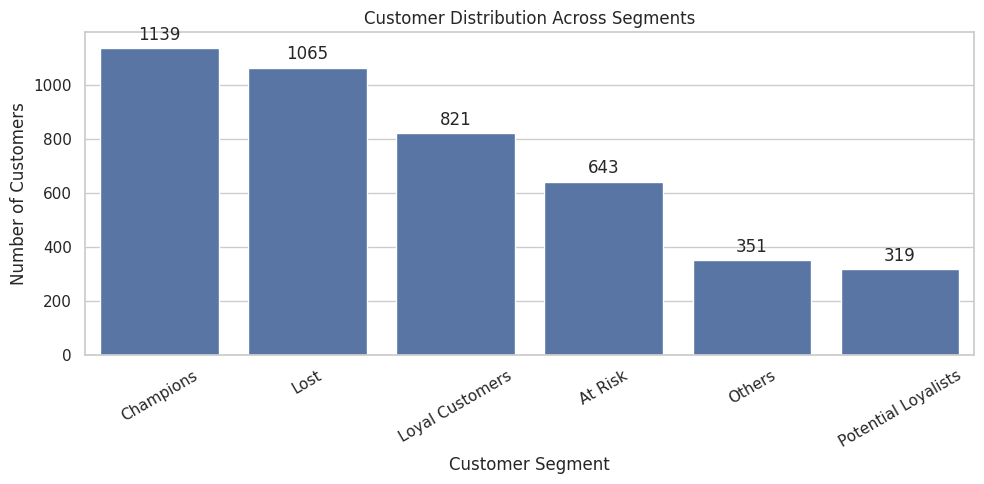

In [44]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=customer_plot,
    x="Segment",
    y="Customers"
)

plt.title("Customer Distribution Across Segments")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

# Display values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.tight_layout()
plt.savefig("customer_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

Chart 2 — Revenue Contribution by Segment

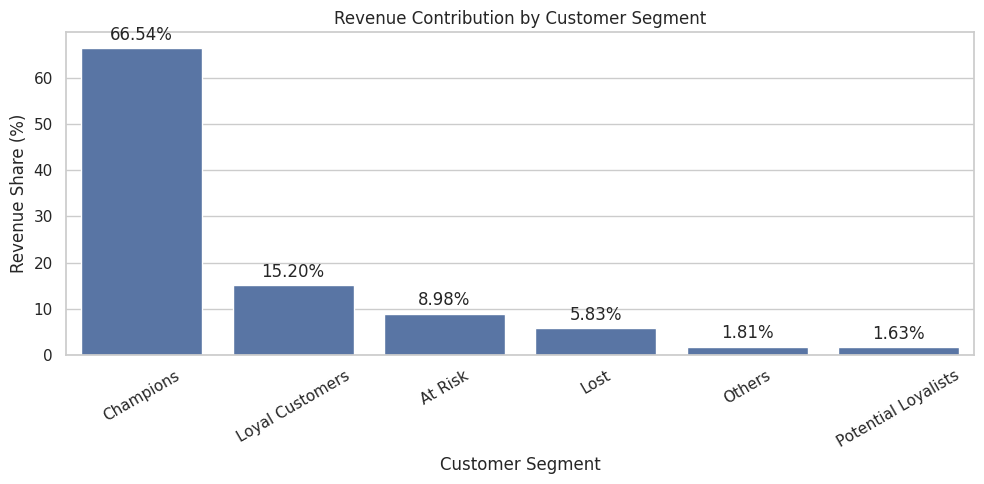

In [45]:
plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=summary,
    x="Segment",
    y="Revenue_%"
)

plt.title("Revenue Contribution by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue Share (%)")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.savefig("revenue_contribution.png", dpi=300, bbox_inches="tight")
plt.show()

Chart 3 — Frequency vs Monetary Scatter Plot

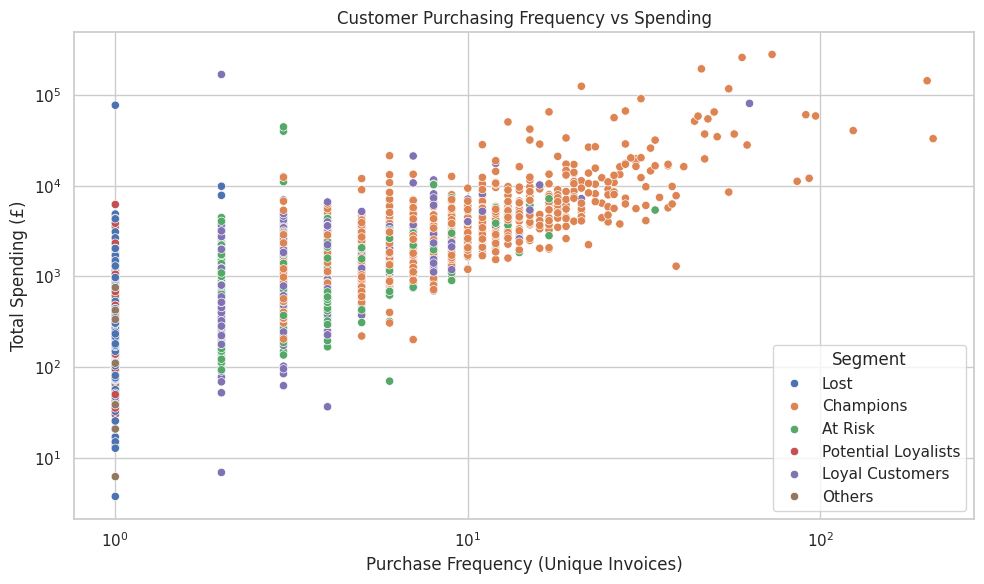

In [41]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm,
    x="Frequency",
    y="Monetary",
    hue="Segment"
)

plt.title("Customer Purchasing Frequency vs Spending")
plt.xlabel("Purchase Frequency (Unique Invoices)")
plt.ylabel("Total Spending (£)")

plt.xscale("log")
plt.yscale("log")

plt.tight_layout()
plt.savefig("frequency_vs_monetary.png", dpi=300, bbox_inches="tight")
plt.show()


Chart 4 — Recency Distribution

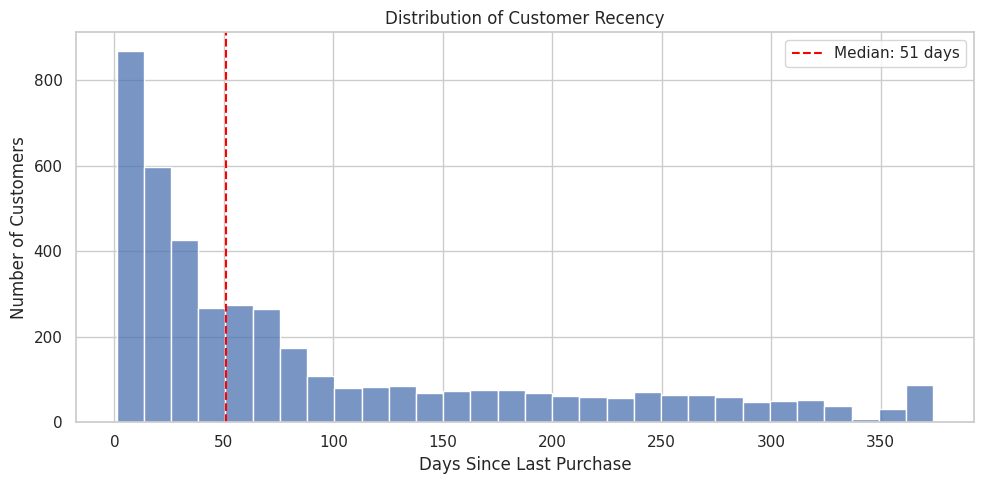

In [46]:
plt.figure(figsize=(10, 5))

sns.histplot(data=rfm, x="Recency", bins=30)

median_recency = rfm["Recency"].median()

plt.axvline(
    median_recency,
    color="red",
    linestyle="--",
    label=f"Median: {median_recency:.0f} days"
)

plt.title("Distribution of Customer Recency")
plt.xlabel("Days Since Last Purchase")
plt.ylabel("Number of Customers")
plt.legend()

plt.tight_layout()
plt.savefig("recency_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

**BUSINESS RECOMMENDATIONS**

In [47]:

# Define business recommendations for each segment

recommendations = {
    "Champions": "Provide loyalty rewards and early access to new products",

    "Loyal Customers": "Encourage upselling, cross-selling and referrals",

    "Potential Loyalists": "Send welcome offers and second-purchase discounts",

    "At Risk": "Launch win-back emails and personalized discounts",

    "Lost": "Try low-cost reactivation campaigns",

    "Others": "Review customer behaviour and test relevant offers"
}

# Add recommendation to each customer
rfm["Recommended_Action"] = rfm["Segment"].map(
    recommendations
)

# Display customer details and recommended actions
display(rfm[
    ["CustomerID", "Segment", "R_score",
     "F_score", "M_score", "Recommended_Action"]
].head(10))


,CustomerID,Segment,R_score,F_score,M_score,Recommended_Action
0,12346.0,Lost,1,1,5,Try low-cost reactivation campaigns
1,12347.0,Champions,5,5,5,Provide loyalty rewards and early access to ne...
2,12348.0,At Risk,2,4,4,Launch win-back emails and personalized discounts
3,12349.0,Potential Loyalists,4,1,4,Send welcome offers and second-purchase discounts
4,12350.0,Lost,1,1,2,Try low-cost reactivation campaigns
5,12352.0,Loyal Customers,3,5,5,"Encourage upselling, cross-selling and referrals"
6,12353.0,Lost,1,1,1,Try low-cost reactivation campaigns
7,12354.0,Lost,1,1,4,Try low-cost reactivation campaigns
8,12355.0,Lost,1,1,2,Try low-cost reactivation campaigns
9,12356.0,Loyal Customers,4,3,5,"Encourage upselling, cross-selling and referrals"


In [48]:

# Create a business recommendation report
recommendation_report = summary[
    ["Segment", "Customers", "Customer_%", "Revenue_%"]
].copy()

recommendation_report["Recommended_Action"] = (
    recommendation_report["Segment"].map(recommendations)
)

display(recommendation_report)


,Segment,Customers,Customer_%,Revenue_%,Recommended_Action
1,Champions,1139,26.26,66.54,Provide loyalty rewards and early access to ne...
3,Loyal Customers,821,18.93,15.20,"Encourage upselling, cross-selling and referrals"
0,At Risk,643,14.82,8.98,Launch win-back emails and personalized discounts
2,Lost,1065,24.55,5.83,Try low-cost reactivation campaigns
4,Others,351,8.09,1.81,Review customer behaviour and test relevant of...
5,Potential Loyalists,319,7.35,1.63,Send welcome offers and second-purchase discounts


## Business Recommendations and Key Findings

### Key Findings

1. Champions represent 26.26% of the customer base and contribute approximately 66% of total revenue, based on the revenue contribution chart.
2. Lost customers account for 24.55% of customers, indicating a significant opportunity to investigate customer inactivity.
3. Loyal Customers represent 18.93% of the customer base and can be encouraged to increase their purchases through upselling and cross-selling.
4. The Recency distribution shows a substantial number of customers with long periods since their last purchase.

### Recommended Business Strategies

- **Champions:** Introduce loyalty rewards, exclusive benefits and early access to new products.
- **Loyal Customers:** Encourage repeat purchases through cross-selling, upselling and referral programs.
- **Potential Loyalists:** Use welcome campaigns and second-purchase offers to develop purchasing habits.
- **At Risk:** Launch targeted win-back email campaigns and personalized discounts.
- **Lost:** Test low-cost reactivation campaigns and evaluate whether further marketing expenditure is justified.
- **Others:** Monitor purchasing behaviour and identify suitable opportunities for targeted promotions.

### Overall Business Strategy

Prioritize retaining Champions, developing Loyal Customers, encouraging Potential Loyalists to make repeat purchases, and testing cost-effective reactivation strategies for At Risk and Lost customers.

In [49]:
summary[
    ["Segment", "Customer_%", "Revenue_%"]
]

,Segment,Customer_%,Revenue_%
1,Champions,26.26,66.54
3,Loyal Customers,18.93,15.20
0,At Risk,14.82,8.98
2,Lost,24.55,5.83
4,Others,8.09,1.81
5,Potential Loyalists,7.35,1.63


OUTPUT FOLDER CREATION

In [50]:

import os

# Create output folder
os.makedirs("outputs", exist_ok=True)

print("Output folder created successfully!")


Output folder created successfully!


In [51]:

clean_df.to_csv(
    "outputs/cleaned_retail_data.csv",
    index=False
)

print("Cleaned dataset exported!")


Cleaned dataset exported!


In [52]:

rfm.to_csv(
    "outputs/rfm_segments.csv",
    index=False
)

print("Customer RFM table exported!")


Customer RFM table exported!


In [53]:

summary.to_csv(
    "outputs/segment_summary.csv",
    index=False
)

print("Segment summary exported!")


Segment summary exported!


In [54]:

print("Files in outputs folder:")
print(os.listdir("outputs"))

print("\nCharts saved in current directory:")
for file in os.listdir("."):
    if file.endswith(".png"):
        print(file)


Files in outputs folder:
['cleaned_retail_data.csv', 'rfm_segments.csv', 'segment_summary.csv']

Charts saved in current directory:
recency_distribution.png
customer_distribution.png
revenue_contribution.png
frequency_vs_monetary.png


In [55]:

import shutil

chart_files = [
    "customer_distribution.png",
    "revenue_contribution.png",
    "frequency_vs_monetary.png",
    "recency_distribution.png"
]

for file in chart_files:
    if os.path.exists(file):
        shutil.move(file, os.path.join("outputs", file))
        print(file, "moved to outputs")
    else:
        print(file, "not found — save that chart first")


customer_distribution.png moved to outputs
revenue_contribution.png moved to outputs
frequency_vs_monetary.png moved to outputs
recency_distribution.png moved to outputs


In [56]:

print("Final output files:")

for file in sorted(os.listdir("outputs")):
    print(file)


Final output files:
cleaned_retail_data.csv
customer_distribution.png
frequency_vs_monetary.png
recency_distribution.png
revenue_contribution.png
rfm_segments.csv
segment_summary.csv


In [57]:

import shutil

shutil.make_archive(
    "rfm_project_outputs",
    "zip",
    "outputs"
)

print("ZIP file created successfully!")


ZIP file created successfully!


In [58]:
from google.colab import files

files.download("rfm_project_outputs.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>